In [5]:

# BÀI 2 - CÂU 1
# Nhập dữ liệu Adult Income và xác định số lượng mẫu train, test

from google.colab import files
import pandas as pd
import io

print("Họ tên: Phạm Hải Yến")
print("MSSV: 6451071091")
print("Bài 2 - Câu 1")
print("-" * 50)

# Upload 2 file từ máy tính
uploaded = files.upload()

# Tên các thuộc tính
columns = [
    "age", "workclass", "fnlwgt", "education",
    "education-num", "marital-status", "occupation",
    "relationship", "race", "sex", "capital-gain",
    "capital-loss", "hours-per-week", "native-country",
    "income"
]

# Tự động tìm tên file đã upload
train_file = next(
    name for name in uploaded.keys()
    if name.startswith("adult.data")
)

test_file = next(
    name for name in uploaded.keys()
    if name.startswith("adult.test")
)

# Đọc dữ liệu huấn luyện
train_df = pd.read_csv(
    io.BytesIO(uploaded[train_file]),
    header=None,
    names=columns,
    skipinitialspace=True
)

# Đọc dữ liệu kiểm thử
test_df = pd.read_csv(
    io.BytesIO(uploaded[test_file]),
    header=None,
    names=columns,
    skipinitialspace=True,
    comment="|"
)

# In số lượng dữ liệu
print("\nTên file huấn luyện:", train_file)
print("Tên file kiểm thử:", test_file)

print("\nSố lượng dữ liệu huấn luyện:",
      train_df.shape[0])

print("Số lượng dữ liệu kiểm thử:",
      test_df.shape[0])

# Hiển thị dữ liệu
print("\n5 dòng đầu tiên của tập huấn luyện:")
display(train_df.head())

print("\n5 dòng đầu tiên của tập kiểm thử:")
display(test_df.head())


Họ tên: Phạm Hải Yến
MSSV: 6451071091
Bài 2 - Câu 1
--------------------------------------------------


Saving adult.data.csv to adult.data.csv
Saving adult.test.csv to adult.test.csv

Tên file huấn luyện: adult.data.csv
Tên file kiểm thử: adult.test.csv

Số lượng dữ liệu huấn luyện: 32562
Số lượng dữ liệu kiểm thử: 16282

5 dòng đầu tiên của tập huấn luyện:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
1,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
2,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
3,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
4,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K



5 dòng đầu tiên của tập kiểm thử:


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income,NaN
1,25,Private,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K,NaN
2,38,Private,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K,NaN
3,28,Local-gov,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K,NaN
4,44,Private,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K,NaN


In [16]:
# BÀI 2 - CÂU 2
# TIẾN HÀNH TIỀN XỬ LÝ DỮ LIỆU

import pandas as pd
import numpy as np

print("Họ tên: Phạm Hải Yến")
print("MSSV: 6451071091")
print("Bài 2 - Câu 2")
print("-" * 50)

# 1. Đọc lại dữ liệu gốc
# File adult.test.csv của bạn có dòng tiêu đề (header)

train_df = pd.read_csv(
    "/content/adult.data.csv",
    skipinitialspace=True
)

test_df = pd.read_csv(
    "/content/adult.test.csv",
    header=0,
    skipinitialspace=True
)

# Xóa khoảng trắng ở tên cột
train_df.columns = train_df.columns.str.strip()
test_df.columns = test_df.columns.str.strip()

# Xóa khoảng trắng ở dữ liệu dạng chuỗi
for df in [train_df, test_df]:
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].str.strip()

# 2. Thay ký hiệu '?' bằng NaN
train_df = train_df.replace("?", np.nan)
test_df = test_df.replace("?", np.nan)

# 3. Xóa các dòng chứa dữ liệu thiếu
train_df = train_df.dropna().copy()
test_df = test_df.dropna().copy()

print("Số dòng train sau khi xóa dữ liệu thiếu:",
      train_df.shape[0])

print("Số dòng test sau khi xóa dữ liệu thiếu:",
      test_df.shape[0])

# 4. Xóa cột fnlwgt nếu tồn tại
train_df = train_df.drop(columns=["fnlwgt"], errors="ignore")
test_df = test_df.drop(columns=["fnlwgt"], errors="ignore")

print("\nCác thuộc tính sau khi xóa fnlwgt:")
print(train_df.columns.tolist())

# 5. Nối dữ liệu huấn luyện và kiểm thử
all_data = pd.concat(
    [train_df, test_df],
    ignore_index=True
)

print("\nKích thước dữ liệu huấn luyện:",
      train_df.shape)

print("Kích thước dữ liệu kiểm thử:",
      test_df.shape)

print("Kích thước dữ liệu sau khi nối:",
      all_data.shape)

# 6. Hiển thị dữ liệu sau tiền xử lý
display(all_data.head())

Họ tên: Phạm Hải Yến
MSSV: 6451071091
Bài 2 - Câu 2
--------------------------------------------------
Số dòng train sau khi xóa dữ liệu thiếu: 30162
Số dòng test sau khi xóa dữ liệu thiếu: 15060

Các thuộc tính sau khi xóa fnlwgt:
['age', 'workclass', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']

Kích thước dữ liệu huấn luyện: (30162, 14)
Kích thước dữ liệu kiểm thử: (15060, 14)
Kích thước dữ liệu sau khi nối: (45222, 14)


,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


Họ tên: Phạm Hải Yến
MSSV: 6451071091
Bài 2 - Câu 3
--------------------------------------------------
Các thuộc tính số:
['age', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

Ma trận tương quan Pearson:


,age,education-num,capital-gain,capital-loss,hours-per-week
age,1.000000,0.037623,0.079683,0.059351,0.101992
education-num,0.037623,1.000000,0.126907,0.081711,0.146206
capital-gain,0.079683,0.126907,1.000000,-0.032102,0.083880
capital-loss,0.059351,0.081711,-0.032102,1.000000,0.054195
hours-per-week,0.101992,0.146206,0.083880,0.054195,1.000000


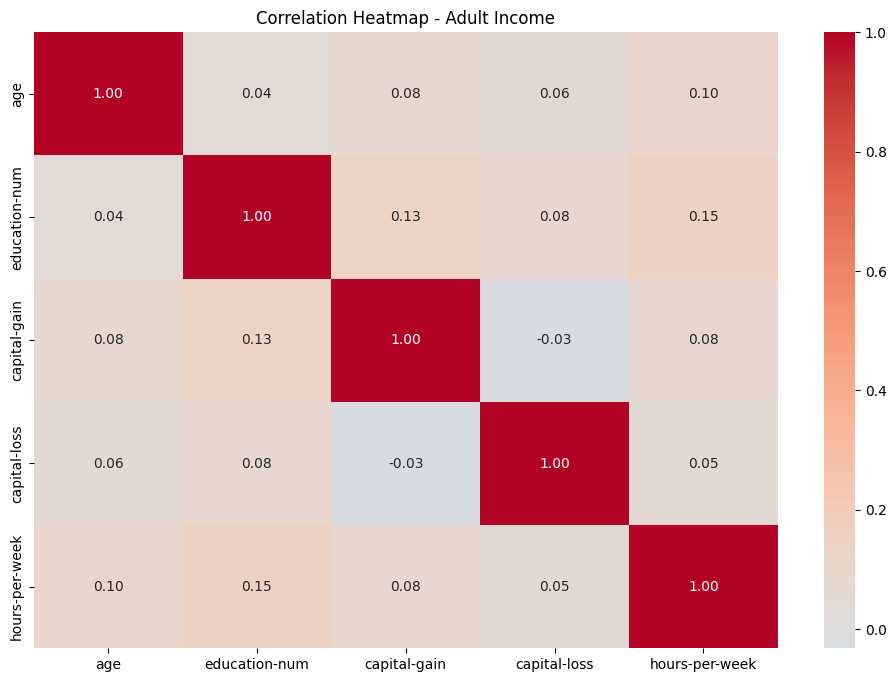


Các cặp thuộc tính tương quan cao:

Các cột bị loại bỏ:
[]

Kích thước dữ liệu sau xử lý:
(45222, 14)


,age,workclass,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


In [17]:

# BÀI 2 - CÂU 3
# KHẢO SÁT ĐỘ TƯƠNG ĐỒNG BẰNG PEARSON

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("Họ tên: Phạm Hải Yến")
print("MSSV: 6451071091")
print("Bài 2 - Câu 3")
print("-" * 50)

# 1. Chuyển các thuộc tính số về đúng kiểu dữ liệu
numeric_columns = [
    "age",
    "education-num",
    "capital-gain",
    "capital-loss",
    "hours-per-week"
]

for col in numeric_columns:
    if col in all_data.columns:
        all_data[col] = pd.to_numeric(
            all_data[col],
            errors="coerce"
        )

# 2. Lấy các thuộc tính dạng số
numeric_data = all_data.select_dtypes(
    include=[np.number]
)

print("Các thuộc tính số:")
print(numeric_data.columns.tolist())

# 3. Tính ma trận tương quan Pearson
corr_matrix = numeric_data.corr(
    method="pearson"
)

print("\nMa trận tương quan Pearson:")
display(corr_matrix)

# 4. Vẽ biểu đồ Heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)

plt.title("Correlation Heatmap - Adult Income")
plt.show()

# 5. Xác định các cặp thuộc tính tương quan cao
threshold = 0.8

upper_triangle = corr_matrix.abs().where(
    np.triu(
        np.ones(corr_matrix.shape),
        k=1
    ).astype(bool)
)

high_corr_pairs = []

for col in upper_triangle.columns:
    for row in upper_triangle.index:
        value = upper_triangle.loc[row, col]

        if pd.notna(value) and value >= threshold:
            high_corr_pairs.append(
                (row, col, value)
            )

print("\nCác cặp thuộc tính tương quan cao:")

for col1, col2, value in high_corr_pairs:
    print(f"{col1} - {col2}: {value:.3f}")

# 6. Loại bỏ thuộc tính tương quan cao
drop_columns = list(
    upper_triangle.columns[
        (upper_triangle >= threshold).any()
    ]
)

print("\nCác cột bị loại bỏ:")
print(drop_columns)

all_data = all_data.drop(
    columns=drop_columns,
    errors="ignore"
)

print("\nKích thước dữ liệu sau xử lý:")
print(all_data.shape)

display(all_data.head())


In [18]:
# Câu 4: Tách thuộc tính đầu vào (X) và thuộc tính quyết định (y)
print("Họ tên: Phạm Hải Yến")
print("MSSV: 6451071091")
print("Bài 2 - Câu 4")

target_column = "income"

# X: các thuộc tính dùng để dự đoán
X = all_data.drop(columns=[target_column])

# y: thuộc tính cần dự đoán
y = all_data[target_column]

print("Kích thước X:", X.shape)
print("Kích thước y:", y.shape)

print("\nCác thuộc tính đầu vào:")
print(X.columns.tolist())

print("\nCác giá trị của thuộc tính quyết định:")
print(y.value_counts())

Họ tên: Phạm Hải Yến
MSSV: 6451071091
Bài 2 - Câu 4
Kích thước X: (45222, 13)
Kích thước y: (45222,)

Các thuộc tính đầu vào:
['age', 'workclass', 'education', 'education-num', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'capital-gain', 'capital-loss', 'hours-per-week', 'native-country']

Các giá trị của thuộc tính quyết định:
income
<=50K    34014
>50K     11208
Name: count, dtype: int64


In [19]:
# Câu 5: Chuyển các thuộc tính không phải dạng số sang one-hot vector

print("Họ tên: Phạm Hải Yến")
print("MSSV: 6451071091")
print("Bài 2 - Câu 5")

import pandas as pd

# X là dữ liệu đầu vào đã tách ở Câu 4
# Tìm các cột có kiểu dữ liệu không phải số
categorical_columns = X.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Các cột cần chuyển đổi:")
print(categorical_columns)

# Chuyển các thuộc tính phân loại thành one-hot vector
X_encoded = pd.get_dummies(
    X,
    columns=categorical_columns,
    dtype=int
)

print("\nKích thước X trước khi chuyển đổi:", X.shape)
print("Kích thước X sau khi chuyển đổi:", X_encoded.shape)

print("\nDữ liệu sau khi chuyển đổi:")
display(X_encoded.head())

Họ tên: Phạm Hải Yến
MSSV: 6451071091
Bài 2 - Câu 5
Các cột cần chuyển đổi:
['workclass', 'education', 'marital-status', 'occupation', 'relationship', 'race', 'sex', 'native-country']

Kích thước X trước khi chuyển đổi: (45222, 13)
Kích thước X sau khi chuyển đổi: (45222, 103)

Dữ liệu sau khi chuyển đổi:


,age,education-num,capital-gain,capital-loss,hours-per-week,workclass_Federal-gov,workclass_Local-gov,workclass_Private,workclass_Self-emp-inc,workclass_Self-emp-not-inc,...,native-country_Portugal,native-country_Puerto-Rico,native-country_Scotland,native-country_South,native-country_Taiwan,native-country_Thailand,native-country_Trinadad&Tobago,native-country_United-States,native-country_Vietnam,native-country_Yugoslavia
0,39,13,2174,0,40,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
1,50,13,0,0,13,0,0,0,0,1,...,0,0,0,0,0,0,0,1,0,0
2,38,9,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
3,53,7,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,1,0,0
4,28,13,0,0,40,0,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0


In [20]:
# Câu 6: Tách dữ liệu huấn luyện và kiểm thử như ban đầu

print("Họ tên: Phạm Hải Yến")
print("MSSV: 6451071091")
print("Bài 2 - Câu 6")

# Lấy X và y từ dữ liệu huấn luyện
X_train = train_df.drop(columns=["income"])
y_train = train_df["income"]

# Lấy X và y từ dữ liệu kiểm thử
X_test = test_df.drop(columns=["income"])
y_test = test_df["income"]

# One-hot encode các thuộc tính phân loại
X_train_encoded = pd.get_dummies(X_train, dtype=int)
X_test_encoded = pd.get_dummies(X_test, dtype=int)

# Đồng bộ các cột giữa train và test
X_train_encoded, X_test_encoded = X_train_encoded.align(
    X_test_encoded,
    join="left",
    axis=1,
    fill_value=0
)

print("Kích thước X_train:", X_train_encoded.shape)
print("Kích thước y_train:", y_train.shape)
print("Kích thước X_test:", X_test_encoded.shape)
print("Kích thước y_test:", y_test.shape)

Họ tên: Phạm Hải Yến
MSSV: 6451071091
Bài 2 - Câu 6
Kích thước X_train: (30162, 103)
Kích thước y_train: (30162,)
Kích thước X_test: (15060, 103)
Kích thước y_test: (15060,)


Họ tên: Phạm Hải Yến
MSSV: 6451071091
Bài 2 - Câu 7
Accuracy: 0.8157370517928287

Classification Report:
              precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.63      0.61      0.62      3700

    accuracy                           0.82     15060
   macro avg       0.75      0.75      0.75     15060
weighted avg       0.81      0.82      0.81     15060


Confusion Matrix:
[[10026  1334]
 [ 1441  2259]]


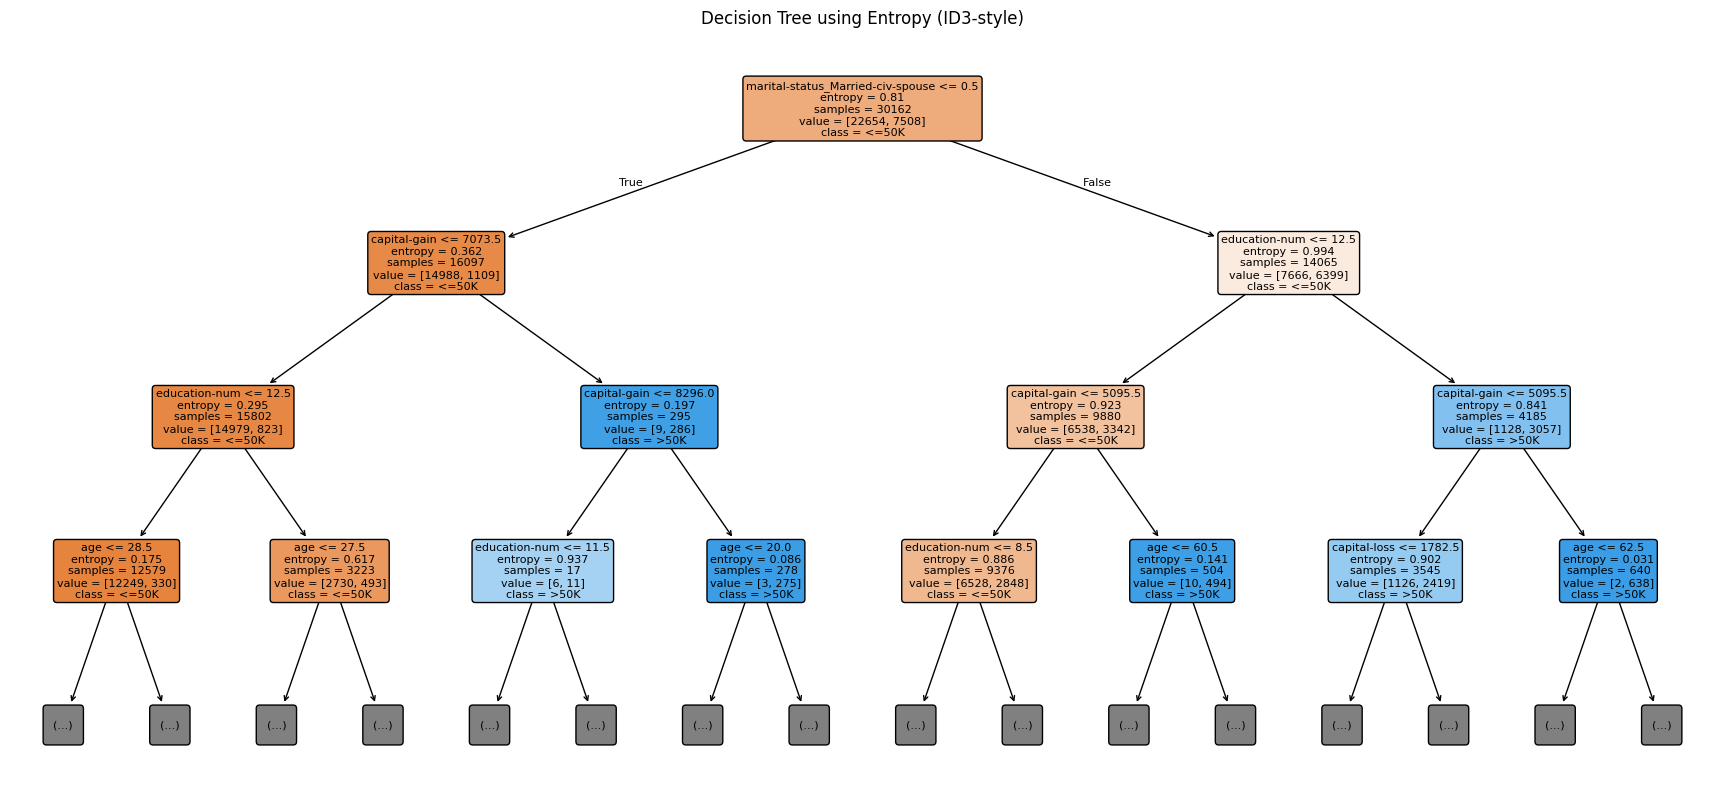

In [21]:
# Câu 7: Xây dựng cây quyết định ID3 và đánh giá kết quả

print("Họ tên: Phạm Hải Yến")
print("MSSV: 6451071091")
print("Bài 2 - Câu 7")

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
import matplotlib.pyplot as plt

# Chuẩn hóa nhãn income:
# adult.test.csv có thể có dấu chấm ở cuối nhãn, ví dụ ">50K."
y_train_id3 = y_train.astype(str).str.strip().str.rstrip(".")
y_test_id3 = y_test.astype(str).str.strip().str.rstrip(".")

# Xây dựng cây quyết định theo Entropy (Information Gain)
id3_model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

# Huấn luyện mô hình
id3_model.fit(X_train_encoded, y_train_id3)

# Dự đoán trên tập kiểm thử
y_pred_id3 = id3_model.predict(X_test_encoded)

# Đánh giá mô hình
print("Accuracy:", accuracy_score(y_test_id3, y_pred_id3))

print("\nClassification Report:")
print(classification_report(y_test_id3, y_pred_id3))

print("\nConfusion Matrix:")
cm = confusion_matrix(
    y_test_id3,
    y_pred_id3,
    labels=["<=50K", ">50K"]
)
print(cm)

# Biểu diễn cây quyết định
plt.figure(figsize=(22, 10))
plot_tree(
    id3_model,
    feature_names=X_train_encoded.columns,
    class_names=id3_model.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)
plt.title("Decision Tree using Entropy (ID3-style)")
plt.show()

Họ tên: Phạm Hải Yến
MSSV: 6451071091
Bài 2 - Câu 8 - Cây CART
--------------------------------------------------
Độ chính xác CART: 0.8129482071713148

Ma trận nhầm lẫn:
[[10006  1354]
 [ 1463  2237]]

Báo cáo phân loại:
              precision    recall  f1-score   support

       <=50K       0.87      0.88      0.88     11360
        >50K       0.62      0.60      0.61      3700

    accuracy                           0.81     15060
   macro avg       0.75      0.74      0.75     15060
weighted avg       0.81      0.81      0.81     15060



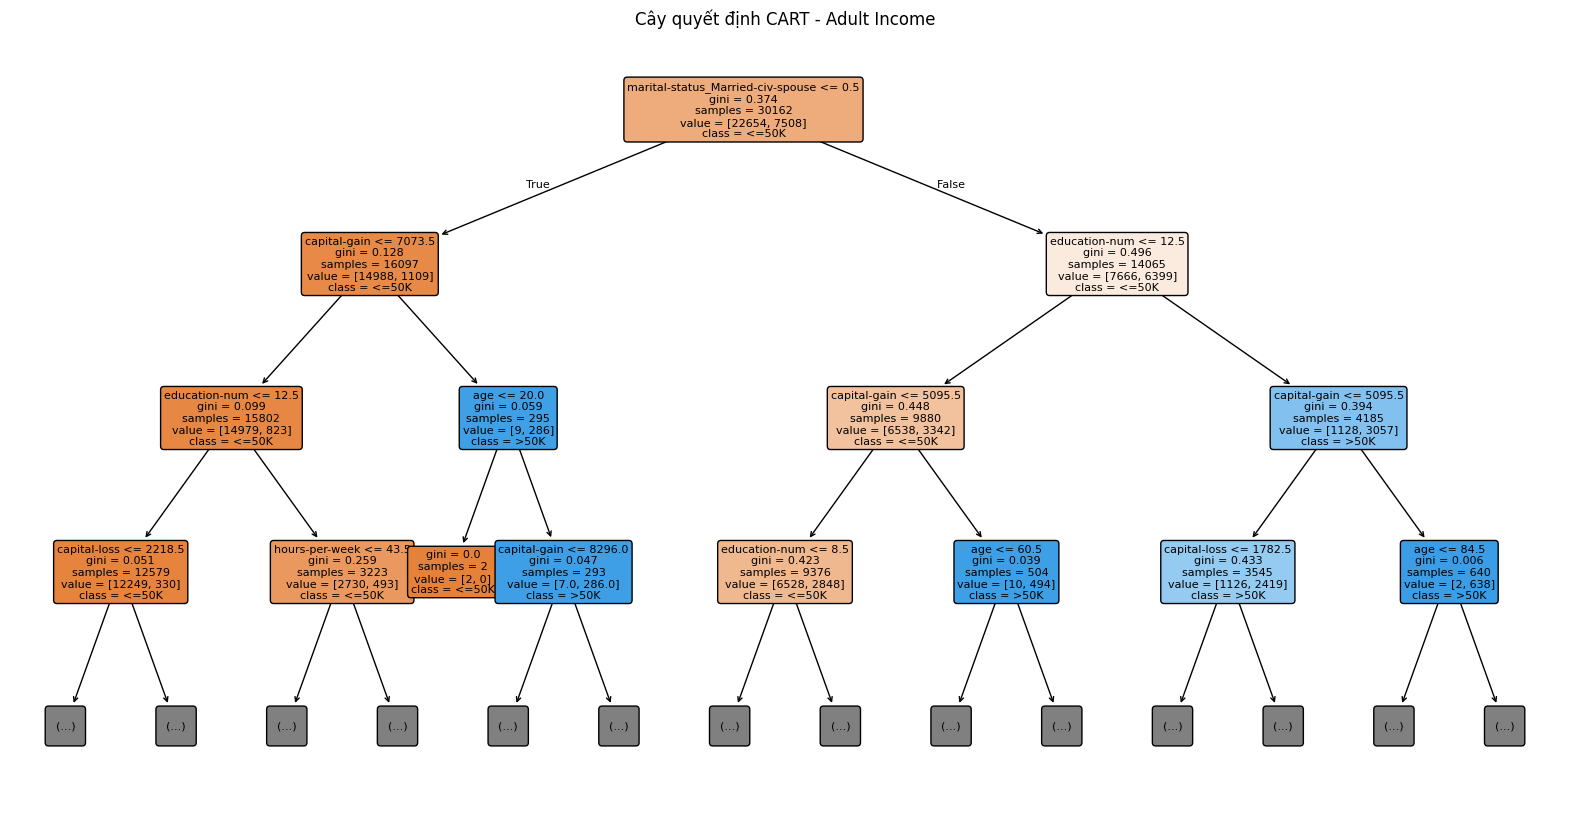

In [22]:
# BÀI 2 - CÂU 8
# XÂY DỰNG CÂY CART VÀ KIỂM THỬ

import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

print("Họ tên: Phạm Hải Yến")
print("MSSV: 6451071091")
print("Bài 2 - Câu 8 - Cây CART")
print("-" * 50)

# 1. Xây dựng mô hình CART
# CART sử dụng Gini làm tiêu chí phân chia mặc định

cart_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

# 2. Huấn luyện mô hình
cart_model.fit(X_train_encoded, y_train)

# 3. Dự đoán trên tập kiểm thử
y_pred_cart = cart_model.predict(X_test_encoded)

# 4. Đánh giá mô hình
print("Độ chính xác CART:",
      accuracy_score(y_test, y_pred_cart))

print("\nMa trận nhầm lẫn:")
print(confusion_matrix(y_test, y_pred_cart))

print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred_cart))

# 5. Biểu diễn cây CART
plt.figure(figsize=(20, 10))

plot_tree(
    cart_model,
    feature_names=X_train_encoded.columns,
    class_names=cart_model.classes_,
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Cây quyết định CART - Adult Income")
plt.show()

Họ tên: Phạm Hải Yến
MSSV: 6451071091
Bài 2 - Câu 9 - Naive Bayes
--------------------------------------------------
Độ chính xác Naive Bayes: 0.8029216467463479

Ma trận nhầm lẫn:
[[9073 2287]
 [ 681 3019]]

Báo cáo phân loại:
              precision    recall  f1-score   support

       <=50K       0.93      0.80      0.86     11360
        >50K       0.57      0.82      0.67      3700

    accuracy                           0.80     15060
   macro avg       0.75      0.81      0.76     15060
weighted avg       0.84      0.80      0.81     15060



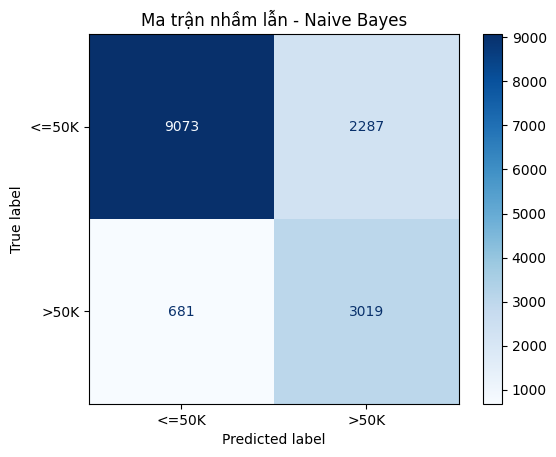

In [23]:
# BÀI 2 - CÂU 9
# XÂY DỰNG MÔ HÌNH NAIVE BAYES

import matplotlib.pyplot as plt
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)

print("Họ tên: Phạm Hải Yến")
print("MSSV: 6451071091")
print("Bài 2 - Câu 9 - Naive Bayes")
print("-" * 50)

# 1. Khởi tạo mô hình Naive Bayes
nb_model = GaussianNB()

# 2. Huấn luyện mô hình
nb_model.fit(X_train_encoded, y_train)

# 3. Dự đoán trên tập kiểm thử
y_pred_nb = nb_model.predict(X_test_encoded)

# 4. Đánh giá mô hình
accuracy_nb = accuracy_score(y_test, y_pred_nb)

print("Độ chính xác Naive Bayes:",
      accuracy_nb)

print("\nMa trận nhầm lẫn:")
cm_nb = confusion_matrix(y_test, y_pred_nb)
print(cm_nb)

print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred_nb))

# 5. Biểu diễn ma trận nhầm lẫn
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_nb,
    display_labels=nb_model.classes_
)

disp.plot(cmap="Blues")
plt.title("Ma trận nhầm lẫn - Naive Bayes")
plt.show()

Họ tên: Phạm Hải Yến
MSSV: 6451071091
Bài 2 - Câu 10 - So sánh mô hình
--------------------------------------------------
Bảng so sánh độ chính xác:


,Mô hình,Độ chính xác
0,ID3,0.815737
1,CART,0.812948
2,Naive Bayes,0.802922


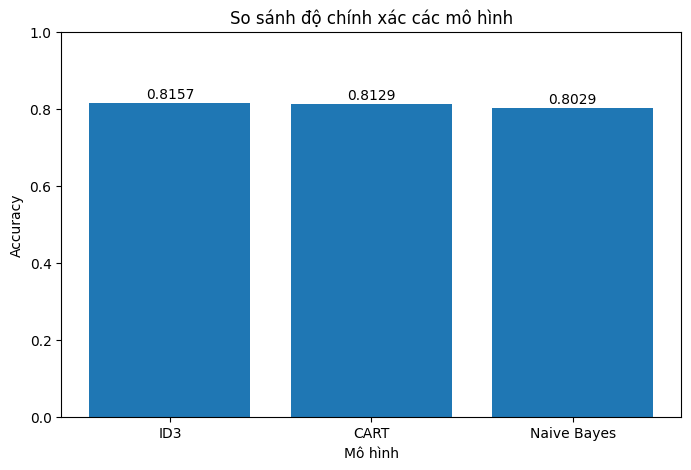


Mô hình có độ chính xác cao nhất: ID3
Độ chính xác: 0.8157370517928287


In [24]:
# BÀI 2 - CÂU 10
# SO SÁNH KẾT QUẢ CÁC MÔ HÌNH

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

print("Họ tên: Phạm Hải Yến")
print("MSSV: 6451071091")
print("Bài 2 - Câu 10 - So sánh mô hình")
print("-" * 50)

# 1. Tính độ chính xác của từng mô hình
accuracy_id3 = accuracy_score(
    y_test,
    y_pred_id3
)

accuracy_cart = accuracy_score(
    y_test,
    y_pred_cart
)

accuracy_nb = accuracy_score(
    y_test,
    y_pred_nb
)

# 2. Tạo bảng so sánh
comparison = pd.DataFrame({
    "Mô hình": [
        "ID3",
        "CART",
        "Naive Bayes"
    ],
    "Độ chính xác": [
        accuracy_id3,
        accuracy_cart,
        accuracy_nb
    ]
})

print("Bảng so sánh độ chính xác:")
display(comparison)

# 3. Vẽ biểu đồ so sánh
plt.figure(figsize=(8, 5))

plt.bar(
    comparison["Mô hình"],
    comparison["Độ chính xác"]
)

plt.title("So sánh độ chính xác các mô hình")
plt.xlabel("Mô hình")
plt.ylabel("Accuracy")
plt.ylim(0, 1)

for i, value in enumerate(comparison["Độ chính xác"]):
    plt.text(
        i,
        value + 0.01,
        f"{value:.4f}",
        ha="center"
    )

plt.show()

# 4. Xác định mô hình có độ chính xác cao nhất
best_model = comparison.loc[
    comparison["Độ chính xác"].idxmax()
]

print(
    "\nMô hình có độ chính xác cao nhất:",
    best_model["Mô hình"]
)

print(
    "Độ chính xác:",
    best_model["Độ chính xác"]
)